In [4]:
from pathlib import Path

ROOT = Path(r"E:\Projects\Deepfake detector")

if not ROOT.exists():
    raise FileNotFoundError(
        f"Project directory not found: {ROOT}\n"
        "Update ROOT to your actual project directory."
    )

print("Project root:", ROOT)

Project root: E:\Projects\Deepfake detector


In [7]:
import torch

checkpoint_paths = {
    "CIFAKE RGB": ROOT / "experiments/rgb-baseline/cifake-image-v2/cifake-rgb-resnet18-best.pt",
    "CIFAKE FFT": ROOT / "experiments/fft-baseline/cifake-image-v2/cifake-fft-resnet18-best.pt",
    "CIFAKE RGB + FFT": ROOT / "experiments/fusion-baseline/cifake-image-v2/cifake-fusion-resnet18-best.pt",
    "FaceForensics++ RGB": ROOT / "experiments/rgb-baseline/faceforensicspp-c23-r2-v1-limited-clean/faceforensicspp-rgb-resnet18-best.pt",
}

for name, path in checkpoint_paths.items():
    print(f"\n{'=' * 55}\n{name}\n{'=' * 55}")

    if not path.is_file():
        print("MISSING:", path)
        continue

    print("Path:", path)
    print(f"Size: {path.stat().st_size / (1024**2):.2f} MiB")

    try:
        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=False,
        )

        if isinstance(checkpoint, dict):
            print("Top-level keys:", list(checkpoint.keys()))

            for key, value in checkpoint.items():
                if isinstance(value, dict):
                    print(f"  {key}: dict ({len(value)} entries)")
                    print("   First keys:", list(value.keys())[:8])
                elif isinstance(value, torch.Tensor):
                    print(f"  {key}: tensor {tuple(value.shape)}")
                else:
                    print(f"  {key}: {type(value).__name__}")
        else:
            print("Loaded object:", type(checkpoint).__name__)

    except Exception as exc:
        print("Could not safely inspect checkpoint:", repr(exc))


CIFAKE RGB
Path: E:\Projects\Deepfake detector\experiments\rgb-baseline\cifake-image-v2\cifake-rgb-resnet18-best.pt
Size: 42.72 MiB
Top-level keys: ['model_state', 'config', 'epoch', 'val_metrics']
  model_state: dict (122 entries)
   First keys: ['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'layer1.0.conv1.weight', 'layer1.0.bn1.weight']
  config: dict (12 entries)
   First keys: ['task', 'manifest_dir', 'output_dir', 'epochs', 'batch_size', 'learning_rate', 'weight_decay', 'seed']
  epoch: int
  val_metrics: dict (2 entries)
   First keys: ['loss', 'accuracy']

CIFAKE FFT
Path: E:\Projects\Deepfake detector\experiments\fft-baseline\cifake-image-v2\cifake-fft-resnet18-best.pt
Size: 42.72 MiB
Top-level keys: ['model_state', 'config', 'epoch', 'val_metrics']
  model_state: dict (122 entries)
   First keys: ['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'layer1.0.

In [6]:
import torch

path = checkpoint_paths["CIFAKE RGB"]

try:
    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False,
    )
    print("Loaded object type:", type(checkpoint))

    if isinstance(checkpoint, dict):
        print("Top-level keys:", list(checkpoint.keys()))

        for key, value in checkpoint.items():
            print(
                key,
                "->",
                type(value).__name__,
                getattr(value, "shape", ""),
            )

except Exception as exc:
    print(type(exc).__name__, str(exc))

Loaded object type: <class 'dict'>
Top-level keys: ['model_state', 'config', 'epoch', 'val_metrics']
model_state -> OrderedDict 
config -> dict 
epoch -> int 
val_metrics -> dict 


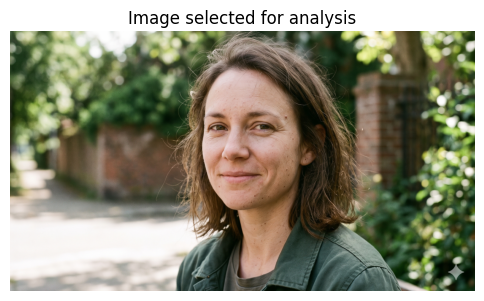

Image path: C:/Users/Dell/Downloads/Gemini_Generated_Image_450a1c450a1c450a.png
Image dimensions: (2752, 1536)


In [8]:
from PIL import Image
import matplotlib.pyplot as plt
from tkinter import Tk, filedialog

root = Tk()
root.withdraw()
root.attributes("-topmost", True)

image_path = filedialog.askopenfilename(
    title="Select an image to analyze",
    filetypes=[
        ("Image files", "*.jpg *.jpeg *.png *.webp *.bmp"),
        ("All files", "*.*"),
    ],
)

root.destroy()

if not image_path:
    raise ValueError("No image selected.")

sample_image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(6, 6))
plt.imshow(sample_image)
plt.title("Image selected for analysis")
plt.axis("off")
plt.show()

print("Image path:", image_path)
print("Image dimensions:", sample_image.size)

In [9]:
for name in [
    "CIFAKE RGB",
    "CIFAKE FFT",
    "CIFAKE RGB + FFT",
]:
    checkpoint = torch.load(
        checkpoint_paths[name],
        map_location="cpu",
        weights_only=False,
    )

    print(f"\n--- {name} ---")
    print("Config:", checkpoint["config"])

    keys = list(checkpoint["model_state"].keys())
    print("Last 20 parameter names:")
    for key in keys[-20:]:
        print(key, tuple(checkpoint["model_state"][key].shape))


--- CIFAKE RGB ---
Config: {'task': 'cifake', 'manifest_dir': WindowsPath('data/metadata/cifake-image-v2'), 'output_dir': WindowsPath('experiments/rgb-baseline/cifake-image-v2'), 'epochs': 1, 'batch_size': 32, 'learning_rate': 0.0001, 'weight_decay': 0.0001, 'seed': 42, 'num_workers': 0, 'max_records': None, 'pretrained': True, 'source_frame_manifest': None}
Last 20 parameter names:
layer4.0.downsample.0.weight (512, 256, 1, 1)
layer4.0.downsample.1.weight (512,)
layer4.0.downsample.1.bias (512,)
layer4.0.downsample.1.running_mean (512,)
layer4.0.downsample.1.running_var (512,)
layer4.0.downsample.1.num_batches_tracked ()
layer4.1.conv1.weight (512, 512, 3, 3)
layer4.1.bn1.weight (512,)
layer4.1.bn1.bias (512,)
layer4.1.bn1.running_mean (512,)
layer4.1.bn1.running_var (512,)
layer4.1.bn1.num_batches_tracked ()
layer4.1.conv2.weight (512, 512, 3, 3)
layer4.1.bn2.weight (512,)
layer4.1.bn2.bias (512,)
layer4.1.bn2.running_mean (512,)
layer4.1.bn2.running_var (512,)
layer4.1.bn2.num_batc

In [10]:
import numpy as np
import torch
from torchvision import transforms

# Use the same device as your models.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Inference device:", device)

# RGB preprocessing: 224x224 + ImageNet normalization.
rgb_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

# FFT preprocessing described in your saved experiment configuration.
def preprocess_fft(image):
    image = image.convert("L").resize((224, 224))

    gray = np.asarray(image, dtype=np.float32) / 255.0
    spectrum = np.fft.fft2(gray)
    spectrum = np.fft.fftshift(spectrum)

    magnitude = np.log1p(np.abs(spectrum)).astype(np.float32)

    # Per-image min-max normalization.
    lo = magnitude.min()
    hi = magnitude.max()
    magnitude = (
        (magnitude - lo) / (hi - lo)
        if hi > lo
        else np.zeros_like(magnitude)
    )

    # Convert 1-channel frequency map to 3 channels.
    fft_tensor = torch.from_numpy(magnitude).unsqueeze(0)
    fft_tensor = fft_tensor.repeat(3, 1, 1)

    return fft_tensor

# Prepare the selected image.
rgb_input = rgb_transform(sample_image).unsqueeze(0).to(device)
fft_input = preprocess_fft(sample_image).unsqueeze(0).to(device)

print("RGB tensor:", tuple(rgb_input.shape))
print("FFT tensor:", tuple(fft_input.shape))

Inference device: cuda
RGB tensor: (1, 3, 224, 224)
FFT tensor: (1, 3, 224, 224)


In [11]:
import time
import pandas as pd
import torch

CLASS_NAMES = ["Real", "AI-generated"]

def predict_logits(model, *inputs):
    model.eval()

    # Warm up separately if measuring production-style latency.
    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.inference_mode():
        logits = model(*inputs)

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed_ms = (time.perf_counter() - start) * 1000

    if logits.ndim != 2 or logits.shape != (1, 2):
        raise ValueError(
            f"Expected logits shaped (1, 2), got {tuple(logits.shape)}"
        )

    probabilities = torch.softmax(logits, dim=1)[0].cpu()

    predicted_index = int(probabilities.argmax().item())

    return {
        "Predicted class": CLASS_NAMES[predicted_index],
        "Real score (%)": round(float(probabilities[0]) * 100, 2),
        "AI-generated score (%)": round(float(probabilities[1]) * 100, 2),
        "Inference time (ms)": round(elapsed_ms, 2),
    }


predictors = {
    "RGB": lambda: predict_logits(rgb_model, rgb_input),
    "FFT": lambda: predict_logits(fft_model, fft_input),
    "RGB + FFT": lambda: predict_logits(
        fusion_model, rgb_input, fft_input
    ),
}

rows = []

for model_name, run_prediction in predictors.items():
    try:
        result = run_prediction()
        rows.append({"Model": model_name, **result})
    except Exception as exc:
        print(f"{model_name} inference failed: {type(exc).__name__}: {exc}")

if rows:
    results_df = pd.DataFrame(rows)
    display(results_df)
else:
    print("No predictions were generated.")

RGB inference failed: NameError: name 'rgb_model' is not defined
FFT inference failed: NameError: name 'fft_model' is not defined
RGB + FFT inference failed: NameError: name 'fusion_model' is not defined
No predictions were generated.
